In [1]:
import matplotlib.pyplot as plt
from matplotlib_inline.backend_inline import set_matplotlib_formats


# Plotting
set_matplotlib_formats("retina")

plt.style.use(
    "https://raw.githubusercontent.com/"
    "ksingh1121/python-plot-style/main/physics.mplstyle"
)


In [2]:
import slmsuite

from slmsuite.hardware.cameraslms import FourierSLM

print("slmsuite version:", slmsuite.__version__)
print("Imports successful.")

slmsuite version: 0.4.1
Imports successful.


c:\Users\admin\AppData\Local\Python\pythoncore-3.12-64\Lib\site-packages\slmsuite\holography\algorithms\_header.py:30: UserWarning: cupy is not installed; using numpy. Install cupy for faster GPU-based holography.
  warnings.warn(


In [3]:
from pathlib import Path

from slmsuite.hardware.slms.meadowlark import Meadowlark

print("SLM imports successful.")

SLM imports successful.


In [ ]:
# Meadowlark paths

SDK_PATH = Path(
    r"C:\Program Files\Meadowlark Optics\Blink 1920 HDMI\SDK"
)

LUT_PATH = Path(
    r"C:\Users\admin\Desktop\Projects\SLM\SLM tests\Scripts\Experiment scripts"
    r"\LUT_locked_759nm_20260811_201109\759nm_KS_global_20260811.lut"
)


print("SDK exists :", SDK_PATH.exists())
print("LUT exists :", LUT_PATH.exists())

# Initialize SLM

slm = Meadowlark(
    slm_number=1,
    sdk_path=str(SDK_PATH),
    lut_path=str(LUT_PATH),
    wav_um=0.7593,
    verbose=True,
)


print("\n=== SLM READY ===")
print("Name       :", slm.name)
print("Shape      :", slm.shape)
print("Wavelength :", slm.wav_um, "um")
print("Pixel pitch:", slm.pitch_um, "um")

SDK exists : True
LUT exists : True
Validating DPI awareness...success
Constructing Blink SDK...

In [ ]:
from pathlib import Path
import numpy as np

WAVEFRONT_PHASE_PATH = Path(
    r"C:\Users\admin\Desktop\Projects\SLM\SLM tests\Scripts\4f alignment scripts"
    r"\YDFC_wavefront_phase_processed_R2p80_50ms_dark.npy"
)

wavefront_phase = np.load(WAVEFRONT_PHASE_PATH)

print("Wavefront shape :", wavefront_phase.shape)
print("SLM shape       :", slm.shape)
print("Finite          :", np.all(np.isfinite(wavefront_phase)))
print("Min             :", wavefront_phase.min())
print("Max             :", wavefront_phase.max())

Wavefront shape : (1200, 1920)
SLM shape       : (1200, 1920)
Finite          : True
Min             : 0.0
Max             : 6.2831762207757835


In [ ]:
slm.source["phase"] = wavefront_phase

In [ ]:
slm.phase_correct = True

In [ ]:
from slmsuite.hardware.cameras.alliedvision import AlliedVision

CAMERA_SERIAL = "015C2"

cam = AlliedVision(
    serial=CAMERA_SERIAL,
    verbose=True,
)


print("\n=== CAMERA READY ===")
print("Shape     :", cam.shape)
print("WOI       :", cam.woi)
print("Exposure  :", cam.exposure_s, "s")
print("Bit depth :", cam.bitdepth)

vmbpy initializing... success
Looking for cameras... success
vmbpy sn '015C2' initializing... success

=== CAMERA READY ===
Shape     : (3672, 5496)
WOI       : (0, 5496, 0, 3672)
Exposure  : 0.000304681 s
Bit depth : 8


c:\Users\admin\AppData\Local\Python\pythoncore-3.12-64\Lib\site-packages\slmsuite\hardware\cameras\camera.py:444: UserWarning: '015C2' _get_image_hw() failed 5 times before quitting.
  warnings.warn(f"'{self.name}' _get_image_hw() failed {failures} times before quitting.")


In [ ]:
from slmsuite.hardware.cameraslms import FourierSLM

fs = FourierSLM(cam, slm)

fourier_path = (
    r"C:\Users\admin\Desktop\Projects\SLM\SLM tests\Scripts"
    r"\After M change\YDFC_fourier_300-1000_plus16_pre-wavefront_00000.h5"
)

loaded_path = fs.load_calibration(
    "fourier",
    file_path=fourier_path
)

print("Loaded:", loaded_path)
print("Calibrations:", fs.calibrations.keys())

Loaded: C:\Users\admin\Desktop\Projects\SLM\SLM tests\Scripts\After M change\YDFC_fourier_300-1000_plus16_pre-wavefront_00000.h5
Calibrations: dict_keys(['fourier'])


Mask shape: (22, 17)
Number of dots: 174


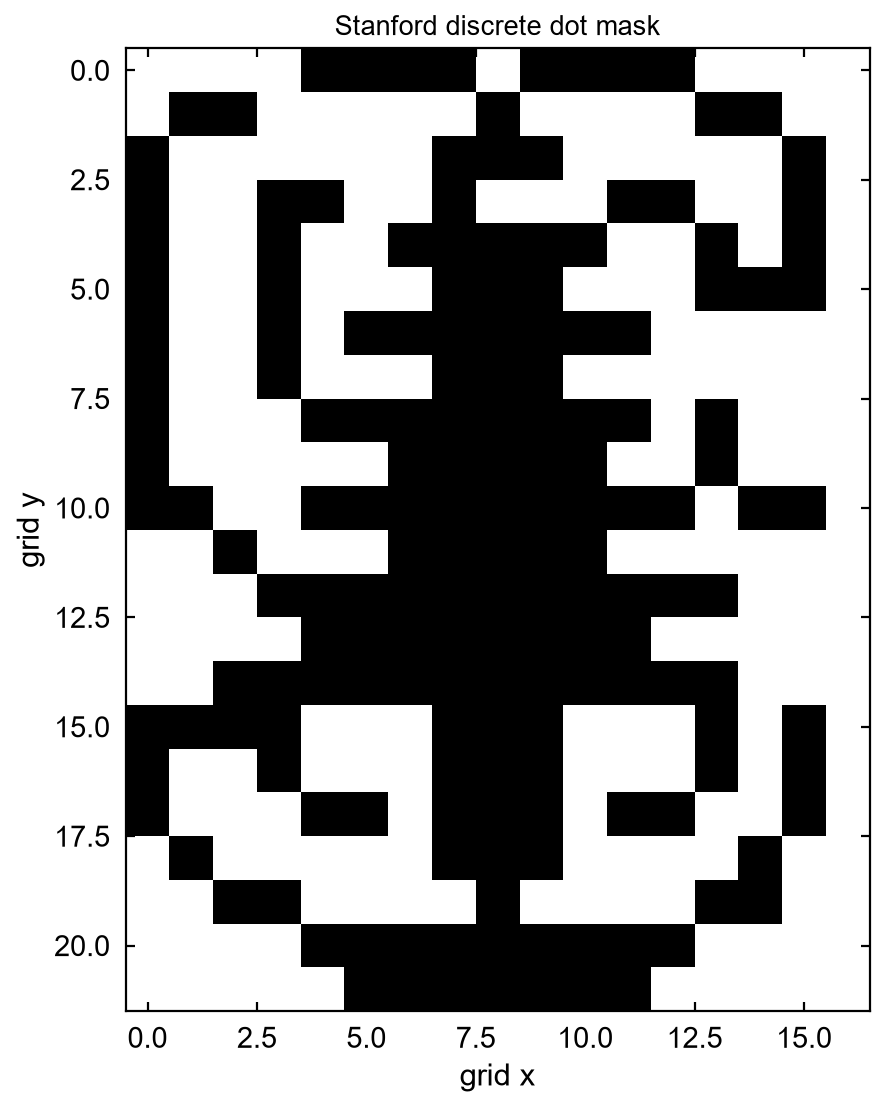

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def make_stanford_dotmask_v2():
    """
    Hand-designed discrete Stanford-style S + tree pattern.
    Returns a boolean mask.
    """

    H, W = 22, 17
    mask = np.zeros((H, W), dtype=bool)

    # Each row lists the occupied dot columns.
    row_points = {
        0:  [4,5,6,7, 9,10,11,12],
        1:  [1,2,      8,      13,14],
        2:  [0,        7,8,9,      15],
        3:  [0, 3,4,   7,      11,12, 15],
        4:  [0, 3,     6,7,8,9,10,    13,15],
        5:  [0, 3,     7,8,9,         13,14,15],
        6:  [0, 3, 5,6,7,8,9,10,11],
        7:  [0, 3,     7,8,9],
        8:  [0, 4,5,6,7,8,9,10,11,   13],
        9:  [0,       6,7,8,9,10,     13],
        10: [0,1,   4,5,6,7,8,9,10,11,12,   14,15],
        11: [2,      6,7,8,9,10],
        12: [3,4,5,6,7,8,9,10,11,12,13],
        13: [4,5,6,7,8,9,10,11],
        14: [2,3,4,5,6,7,8,9,10,11,12,13],
        15: [0,1,2,3,   7,8,9,   13,15],
        16: [0,   3,    7,8,9,   13,15],
        17: [0,   4,5,  7,8,9,   11,12,15],
        18: [1,        7,8,9,         14],
        19: [2,3,      8,            13,14],
        20: [4,5,6,7,8,9,10,11,12],
        21: [5,6,7,8,9,10,11],
    }

    for r, cols in row_points.items():
        for c in cols:
            mask[r, c] = True

    return mask


logo_mask = make_stanford_dotmask_v2()

print("Mask shape:", logo_mask.shape)
print("Number of dots:", np.sum(logo_mask))

plt.figure(figsize=(6, 8))
plt.imshow(logo_mask, cmap="gray_r", interpolation="nearest")
plt.title("Stanford discrete dot mask")
plt.xlabel("grid x")
plt.ylabel("grid y")
plt.show()

Number of spots: 174
x knm range: 1104.0 to 1194.0
y knm range: 961.0 to 1087.0


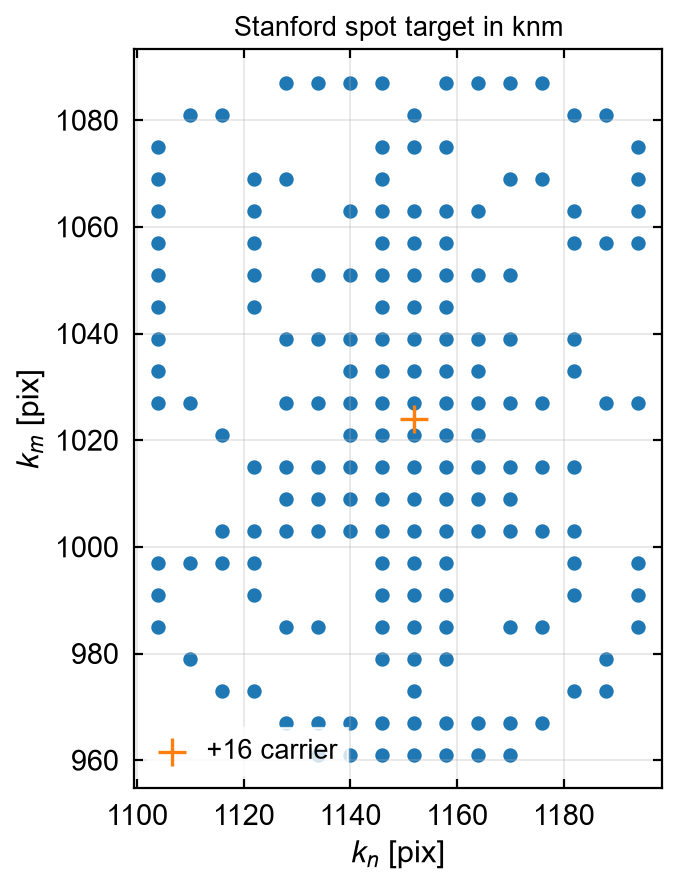

In [ ]:
# ------------------------------------------------------------
# Convert mask -> spot coordinates in knm
# ------------------------------------------------------------

rows, cols = np.where(logo_mask)

Hgrid, Wgrid = logo_mask.shape

dx_sites = cols - (Wgrid - 1) / 2
dy_sites = rows - (Hgrid - 1) / 2

carrier_knm = np.array([1152.0, 1024.0])   # +16-pixel carrier
PITCH_KNM = 6                              # ~4.86 um in atom plane

x_knm = carrier_knm[0] + PITCH_KNM * dx_sites
y_knm = carrier_knm[1] - PITCH_KNM * dy_sites

spot_vectors_knm = np.vstack([x_knm, y_knm])

print("Number of spots:", spot_vectors_knm.shape[1])
print("x knm range:", spot_vectors_knm[0].min(), "to", spot_vectors_knm[0].max())
print("y knm range:", spot_vectors_knm[1].min(), "to", spot_vectors_knm[1].max())

plt.figure(figsize=(6, 6))
plt.scatter(spot_vectors_knm[0], spot_vectors_knm[1], s=30)
plt.scatter(carrier_knm[0], carrier_knm[1], marker="+", s=150, label="+16 carrier")
plt.gca().set_aspect("equal")
plt.xlabel(r"$k_n$ [pix]")
plt.ylabel(r"$k_m$ [pix]")
plt.title("Stanford spot target in knm")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [ ]:
from slmsuite.holography.algorithms import SpotHologram

HOLO_SHAPE = (2048, 2048)

holo_stanford = SpotHologram(
    shape=HOLO_SHAPE,
    spot_vectors=spot_vectors_knm,
    basis="knm",
    cameraslm=fs
)

print("SpotHologram created.")
print("Number of spots:", spot_vectors_knm.shape[1])

SpotHologram created.
Number of spots: 174


In [ ]:
print(fs.calibrations["fourier"]["M"])
print(fs.calibrations["fourier"]["b"])
print(fs.calibrations["fourier"]["a"])

[[ 127279.73025868     293.23159981]
 [    450.42127708 -125110.53609542]]
[[2799.33492288]
 [1157.53158414]]
[[5.93203125e-03]
 [5.63221908e-20]]


In [ ]:
holo_stanford = SpotHologram(
    shape=HOLO_SHAPE,
    spot_vectors=spot_vectors_knm,
    basis="knm",
    cameraslm=fs
)

In [ ]:
holo_stanford = SpotHologram(
    shape=HOLO_SHAPE,
    spot_vectors=spot_vectors_knm,
    basis="knm",
    cameraslm=fs
)

print("SpotHologram created.")
print("Number of spots:", spot_vectors_knm.shape[1])

SpotHologram created.
Number of spots: 174


In [ ]:
holo_stanford.optimize(
    method="WGS-Kim",
    maxiter=50,
    feedback="computational_spot",
    stat_groups=["computational_spot"]
)

  0%|          | 0/50 [00:00<?, ?it/s]

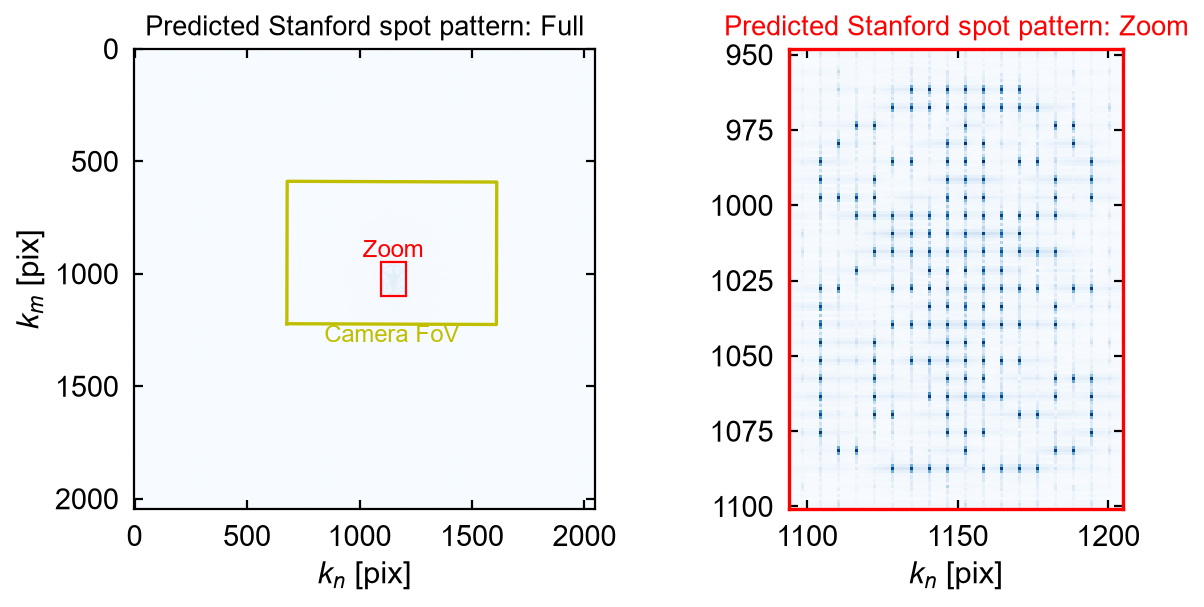

[array([1094, 1205]), array([ 948, 1101])]

In [ ]:
holo_stanford.plot_farfield(
    title="Predicted Stanford spot pattern"
)

In [ ]:
phase_stanford = holo_stanford.get_phase()

print("All finite:", np.all(np.isfinite(phase_stanford)))
print("NaNs:", np.isnan(phase_stanford).sum())
print("Infs:", np.isinf(phase_stanford).sum())
print("Phase shape:", phase_stanford.shape)

slm.write(phase_stanford)

All finite: True
NaNs: 0
Infs: 0
Phase shape: (1200, 1920)


In [ ]:
cam.set_exposure(0.0005)

img_stanford = cam.get_image()

print("Image shape:", img_stanford.shape)
print("Min:", img_stanford.min())
print("Max:", img_stanford.max())
print("Saturated pixels:", np.sum(img_stanford >= 255))

Image shape: (3672, 5496)
Min: 0
Max: 255
Saturated pixels: 10080


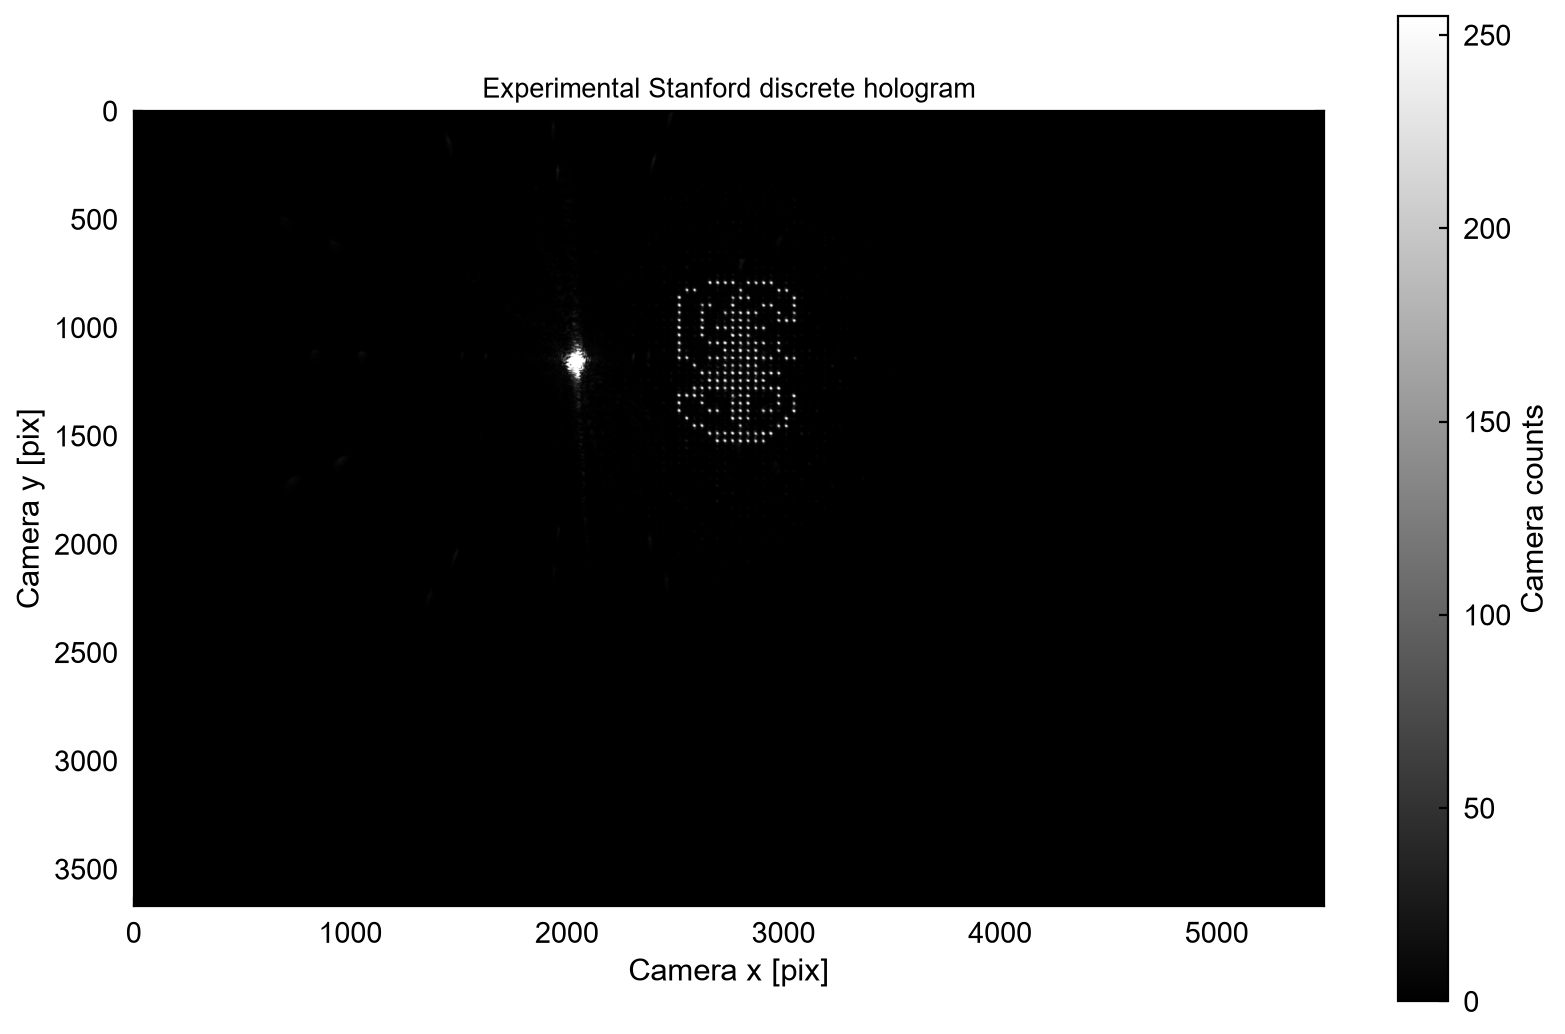

In [ ]:
plt.figure(figsize=(12, 8))
plt.imshow(img_stanford, cmap="gray")
plt.colorbar(label="Camera counts")
plt.title("Experimental Stanford discrete hologram")
plt.xlabel("Camera x [pix]")
plt.ylabel("Camera y [pix]")
plt.show()

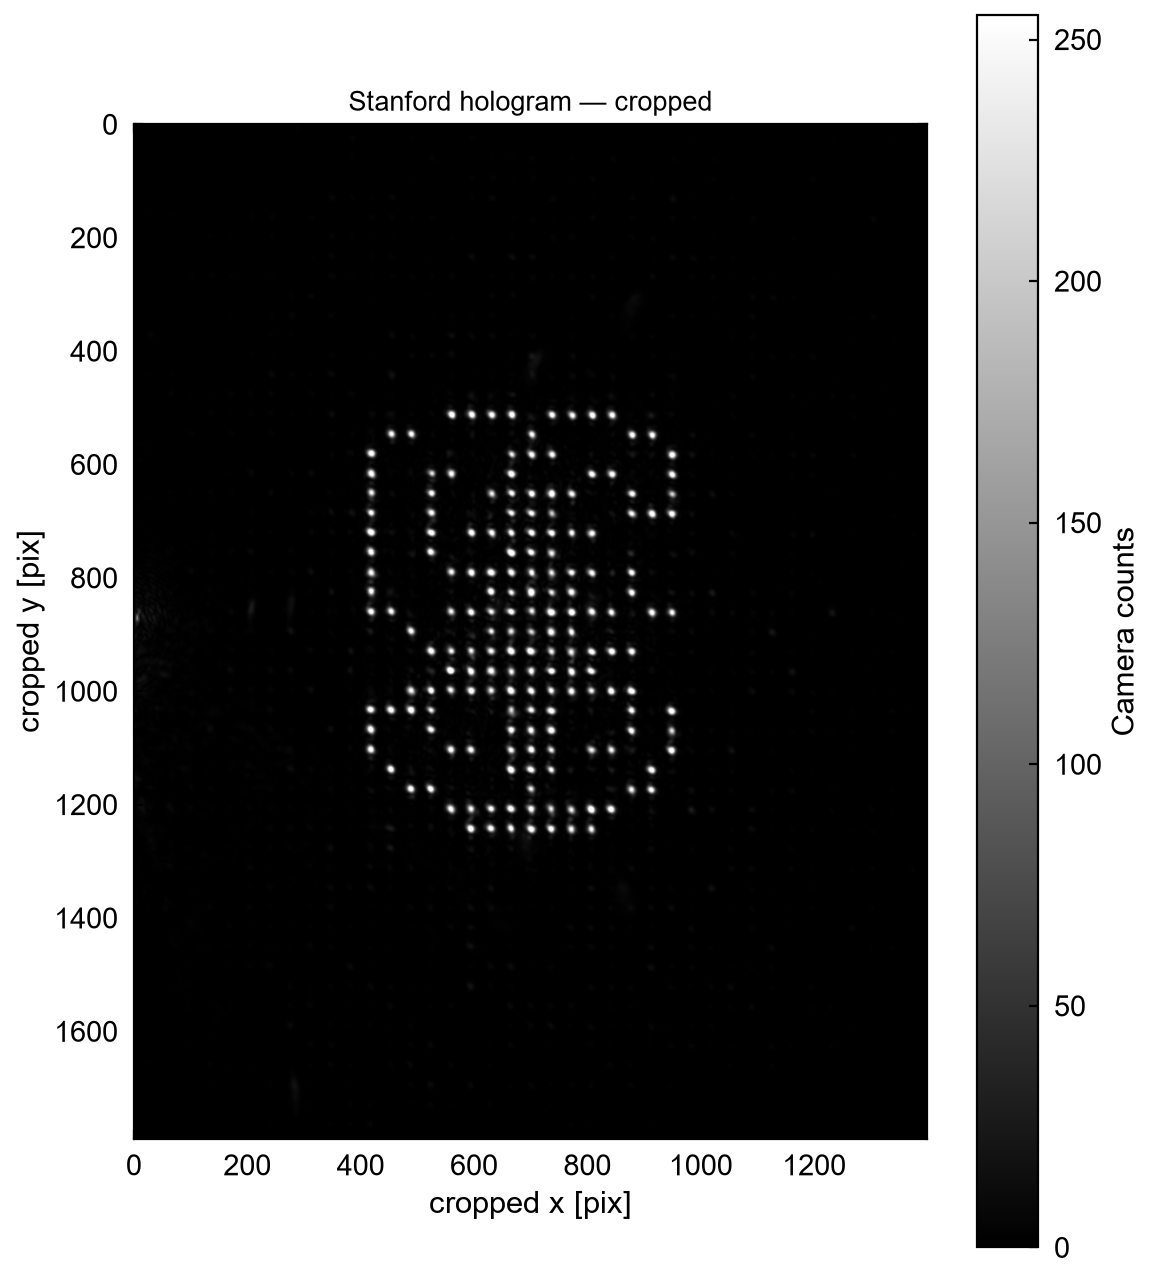

In [ ]:
x1, x2 = 2100, 3500
y1, y2 = 280, 2070

logo_crop = img_stanford[y1:y2, x1:x2]

plt.figure(figsize=(8, 10))
plt.imshow(logo_crop, cmap="gray", origin="upper")
plt.colorbar(label="Camera counts")
plt.title("Stanford hologram — cropped")
plt.xlabel("cropped x [pix]")
plt.ylabel("cropped y [pix]")
plt.show()

# plt.figure(figsize=(10, 8))
# plt.imshow(
#     img_stanford,
#     cmap="gray",
#     vmin=0,
#     vmax=max(20, np.percentile(img_stanford, 99.8))
# )
# plt.xlim(2200, 3400)
# plt.ylim(1800, 600)
# plt.colorbar(label="Camera counts")
# plt.title("Experimental Stanford hologram — zoom")
# plt.xlabel("Camera x [pix]")
# plt.ylabel("Camera y [pix]")
# plt.show()

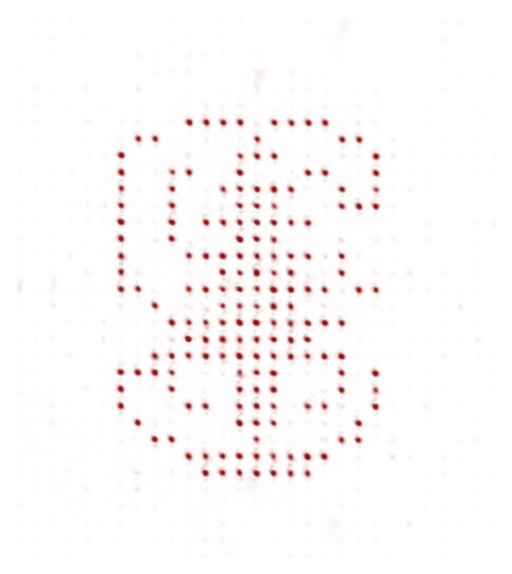

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

stanford_red = "#8C1515"

white_to_cardinal = LinearSegmentedColormap.from_list(
    "white_to_cardinal",
    ["#FFFFFF", stanford_red]
)

x1, x2 = 2300, 3300
y1, y2 = 570, 1700

logo_crop = img_stanford[y1:y2, x1:x2]

plt.figure(figsize=(3,4), facecolor="white")
ax = plt.gca()
ax.set_facecolor("white")

plt.imshow(
    logo_crop,
    cmap=white_to_cardinal,
    origin="upper"
)

# Remove everything
ax.set_xticks([])
ax.set_yticks([])
for spine in ax.spines.values():
    spine.set_visible(False)

plt.tight_layout(pad=0)
plt.show()

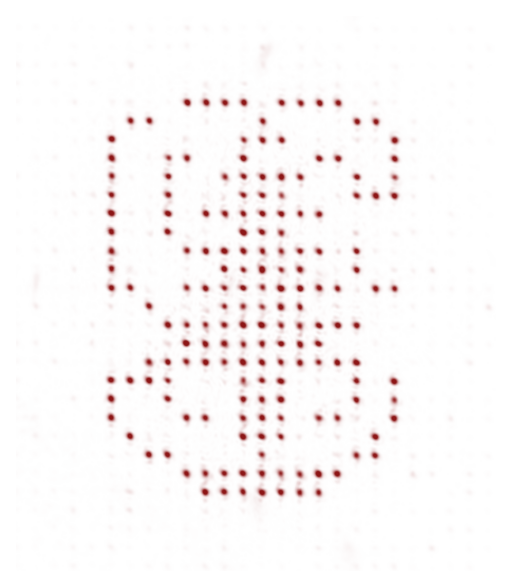

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

stanford_red = "#8C1515"

white_to_cardinal = LinearSegmentedColormap.from_list(
    "white_to_cardinal",
    ["#FFFFFF", stanford_red]
)

x1, x2 = 2340, 3240
y1, y2 = 630, 1671

logo_crop = img_stanford[y1:y2, x1:x2]

plt.figure(figsize=(3,4), facecolor="white")
ax = plt.gca()
ax.set_facecolor("white")

plt.imshow(
    logo_crop,
    cmap=white_to_cardinal,
    origin="upper",
    vmin=0,
    vmax=255
)

# remove all axes / ticks / frame
ax.set_xticks([])
ax.set_yticks([])
for spine in ax.spines.values():
    spine.set_visible(False)

plt.tight_layout(pad=0)
plt.show()

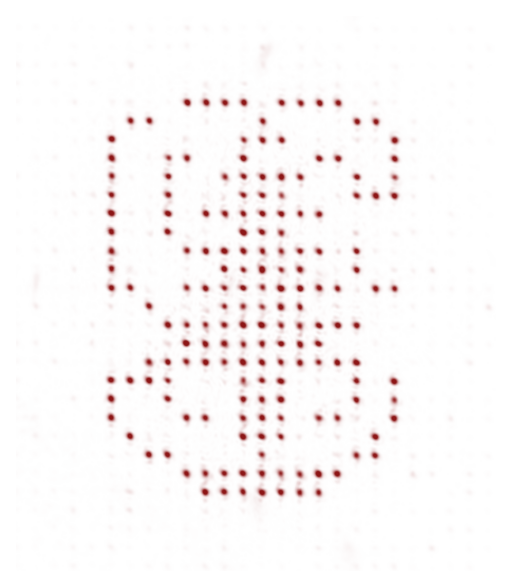

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

stanford_red = "#8C1515"

white_to_cardinal = LinearSegmentedColormap.from_list(
    "white_to_cardinal",
    ["#FFFFFF", stanford_red]
)

x1, x2 = 2340, 3240
y1, y2 = 630, 1671

logo_crop = img_stanford[y1:y2, x1:x2]

fig = plt.figure(figsize=(3,4), facecolor="white")
ax = plt.gca()
ax.set_facecolor("white")

ax.imshow(
    logo_crop,
    cmap=white_to_cardinal,
    origin="upper",
    vmin=0,
    vmax=255
)

# remove all axes / ticks / frame
ax.set_xticks([])
ax.set_yticks([])
for spine in ax.spines.values():
    spine.set_visible(False)

plt.tight_layout(pad=0)

# SAVE BEFORE SHOW
fig.savefig(
    "stanford_logo_highres.png",
    dpi=600,
    bbox_inches="tight",
    pad_inches=0,
    facecolor="white"
)

plt.show()